In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nelgiriyewithana/global-weather-repository/GlobalWeatherRepository.csv
/kaggle/input/datasets/nelgiriyewithana/global-weather-repository/state.db


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nelgiriyewithana/global-weather-repository")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/nelgiriyewithana/global-weather-repository


In [3]:
df = pd.read_csv('/kaggle/input/datasets/nelgiriyewithana/global-weather-repository/GlobalWeatherRepository.csv')
df.head()


,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text,...,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
0,Afghanistan,Kabul,34.52,69.18,Asia/Kabul,1715849100,2024-05-16 13:15,26.6,79.8,Partly Cloudy,...,8.4,26.6,1,1,04:50 AM,06:50 PM,12:12 PM,01:11 AM,Waxing Gibbous,55
1,Albania,Tirana,41.33,19.82,Europe/Tirane,1715849100,2024-05-16 10:45,19.0,66.2,Partly cloudy,...,1.1,2.0,1,1,05:21 AM,07:54 PM,12:58 PM,02:14 AM,Waxing Gibbous,55
2,Algeria,Algiers,36.76,3.05,Africa/Algiers,1715849100,2024-05-16 09:45,23.0,73.4,Sunny,...,10.4,18.4,1,1,05:40 AM,07:50 PM,01:15 PM,02:14 AM,Waxing Gibbous,55
3,Andorra,Andorra La Vella,42.50,1.52,Europe/Andorra,1715849100,2024-05-16 10:45,6.3,43.3,Light drizzle,...,0.7,0.9,1,1,06:31 AM,09:11 PM,02:12 PM,03:31 AM,Waxing Gibbous,55
4,Angola,Luanda,-8.84,13.23,Africa/Luanda,1715849100,2024-05-16 09:45,26.0,78.8,Partly cloudy,...,183.4,262.3,5,10,06:12 AM,05:55 PM,01:17 PM,12:38 AM,Waxing Gibbous,55


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170928 entries, 0 to 170927
Data columns (total 41 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   country                       170928 non-null  object 
 1   location_name                 170928 non-null  object 
 2   latitude                      170928 non-null  float64
 3   longitude                     170928 non-null  float64
 4   timezone                      170928 non-null  object 
 5   last_updated_epoch            170928 non-null  int64  
 6   last_updated                  170928 non-null  object 
 7   temperature_celsius           170928 non-null  float64
 8   temperature_fahrenheit        170928 non-null  float64
 9   condition_text                170928 non-null  object 
 10  wind_mph                      170928 non-null  float64
 11  wind_kph                      170928 non-null  float64
 12  wind_degree                   170928 non-nul

In [5]:
# Convert time column
df['last_updated'] = pd.to_datetime(df['last_updated'])

# Drop duplicates
df = df.drop_duplicates()

# Handle missing values
df = df.dropna()

In [7]:
# Time-based features
df['hour'] = df['last_updated'].dt.hour
df['day'] = df['last_updated'].dt.day

# Day/Night feature
df['is_day'] = df['hour'].apply(lambda x: 1 if 6 <= x <= 18 else 0)

# Encode country (useful for ML)
df['country_encoded'] = df['country'].astype('category').cat.codes

# Extract time features
df['hour'] = df['last_updated'].dt.hour
df['day'] = df['last_updated'].dt.day

# Day/Night feature
df['is_day'] = df['hour'].apply(lambda x: 1 if 6 <= x <= 18 else 0)

print(df[['last_updated', 'hour', 'day', 'is_day']].head())

         last_updated  hour  day  is_day
0 2024-05-16 13:15:00    13   16       1
1 2024-05-16 10:45:00    10   16       1
2 2024-05-16 09:45:00     9   16       1
3 2024-05-16 10:45:00    10   16       1
4 2024-05-16 09:45:00     9   16       1


In [8]:
#EDA

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_style("whitegrid")

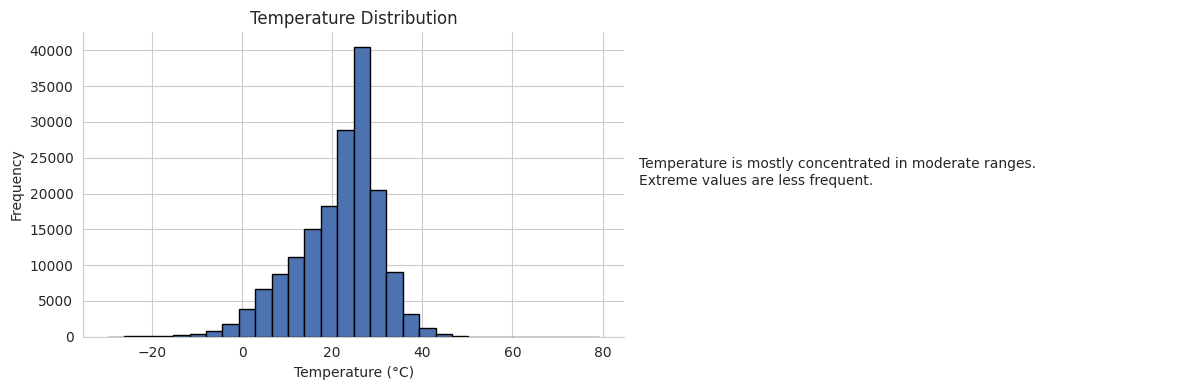

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))

counts, bins, patches = ax[0].hist(
    df['temperature_celsius'],
    bins=30,
    color="#4C72B0",
    edgecolor='black'
)

ax[0].set_title("Temperature Distribution")
ax[0].set_xlabel("Temperature (°C)")
ax[0].set_ylabel("Frequency")

ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

# Text
ax[1].axis('off')
ax[1].text(0, 0.5,
           "Temperature is mostly concentrated in moderate ranges.\n"
           "Extreme values are less frequent.",
           fontsize=10)

plt.tight_layout()
plt.show()

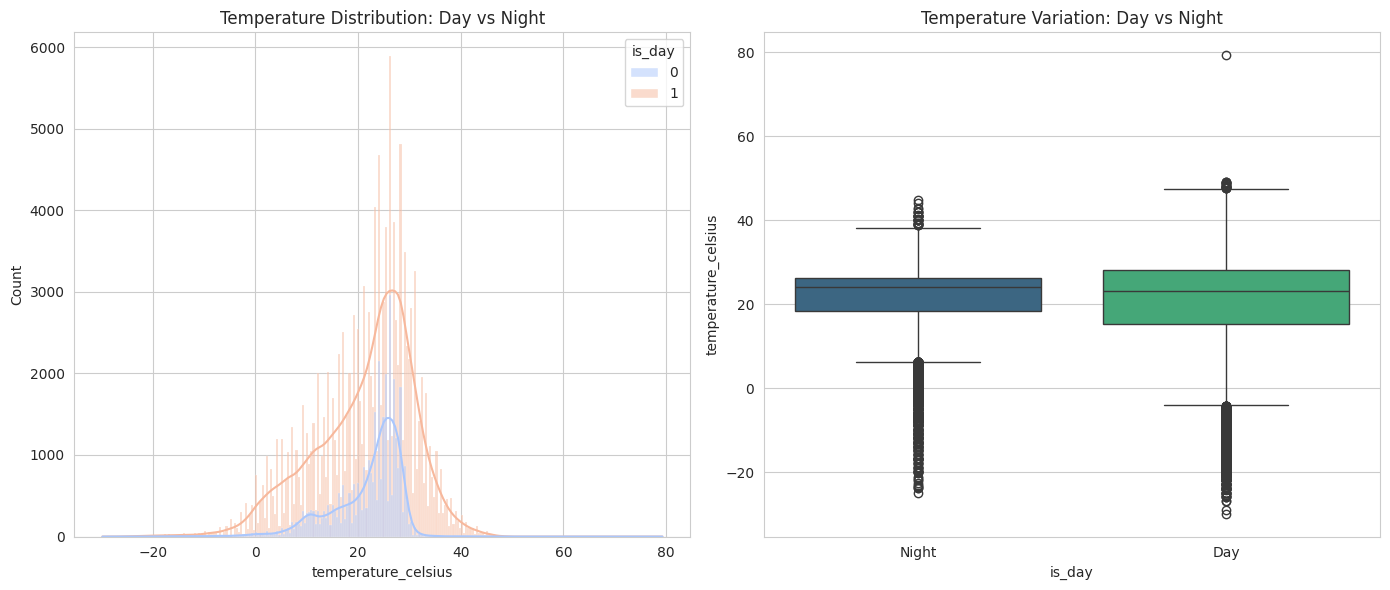

In [10]:
plt.figure(figsize=(14,6))

# Temperature Distribution
plt.subplot(1, 2, 1)
sns.histplot(
    data=df,
    x='temperature_celsius',
    hue='is_day',
    kde=True,
    palette='coolwarm'
)
plt.title('Temperature Distribution: Day vs Night')


# Boxplot Comparison
plt.subplot(1, 2, 2)
sns.boxplot(
    data=df,
    x='is_day',
    y='temperature_celsius',
    hue='is_day',
    palette='viridis',
    legend=False
)

plt.xticks([0,1], ['Night','Day'])
plt.title('Temperature Variation: Day vs Night')

plt.tight_layout()
plt.show()


In [11]:
#Top polluted Cities


top_polluted = df.sort_values(by='air_quality_PM2.5', ascending=False).head(10)
print(top_polluted[['location_name', 'country', 'air_quality_PM2.5']])

      location_name country  air_quality_PM2.5
4125       Santiago   Chile             1614.1
4513       Santiago   Chile             1406.3
12219      Santiago   Chile             1204.9
3930       Santiago   Chile             1190.5
14338      Santiago   Chile             1188.4
9540       Santiago   Chile             1119.7
9345       Santiago   Chile             1116.0
2955       Santiago   Chile             1078.5
3150       Santiago   Chile             1018.7
3735       Santiago   Chile             1012.9


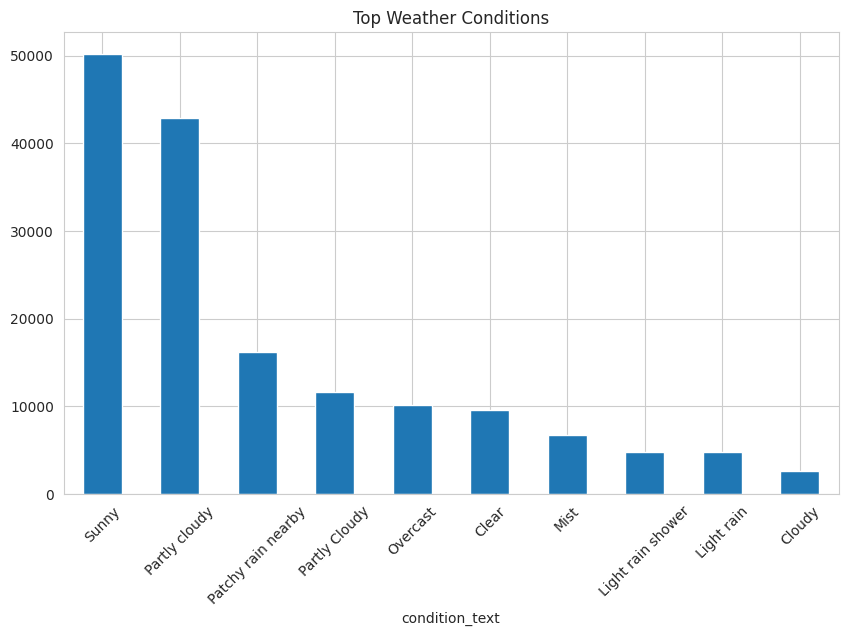

In [12]:
# Weather Condition Count

df['condition_text'].value_counts().head(10).plot(kind='bar', figsize=(10,6))
plt.title("Top Weather Conditions")
plt.xticks(rotation=45)
plt.show()

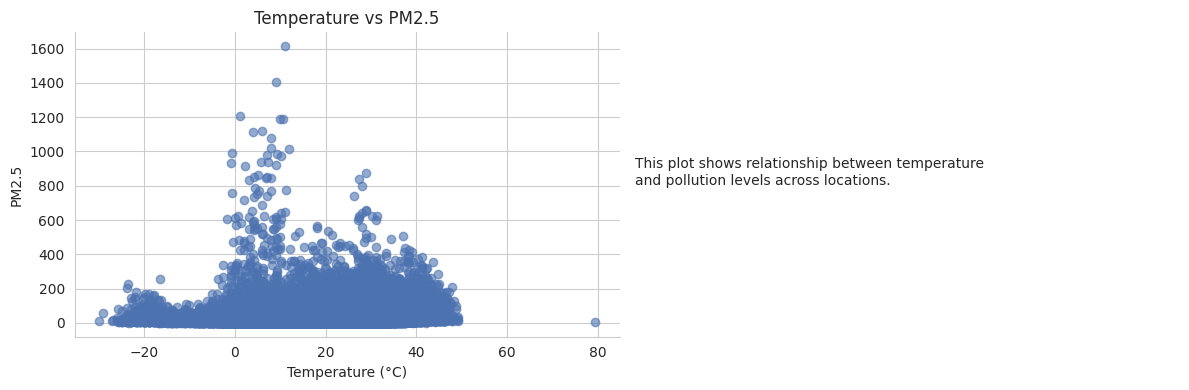

In [13]:
#Temperature vs PM2.5


fig, ax = plt.subplots(1, 2, figsize=(12,4))

ax[0].scatter(df['temperature_celsius'], df['air_quality_PM2.5'], color="#4C72B0", alpha=0.6)
ax[0].set_title("Temperature vs PM2.5")
ax[0].set_xlabel("Temperature (°C)")
ax[0].set_ylabel("PM2.5")

ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

ax[1].axis('off')
ax[1].text(0, 0.5,
           "This plot shows relationship between temperature\n"
           "and pollution levels across locations.",
           fontsize=10)

plt.tight_layout()
plt.show()

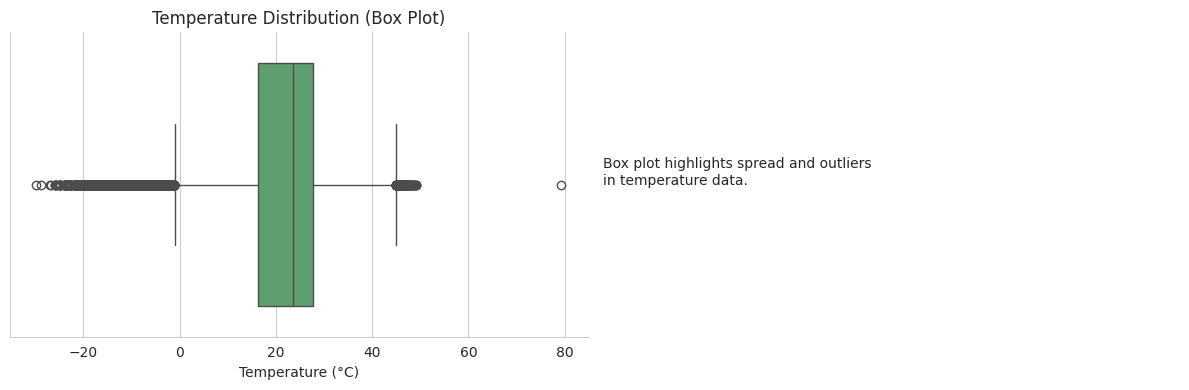

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))

sns.boxplot(x=df['temperature_celsius'], ax=ax[0], color="#55A868")
ax[0].set_title("Temperature Distribution (Box Plot)")
ax[0].set_xlabel("Temperature (°C)")

ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

ax[1].axis('off')
ax[1].text(0, 0.5,
           "Box plot highlights spread and outliers\n"
           "in temperature data.",
           fontsize=10)

plt.tight_layout()
plt.show()

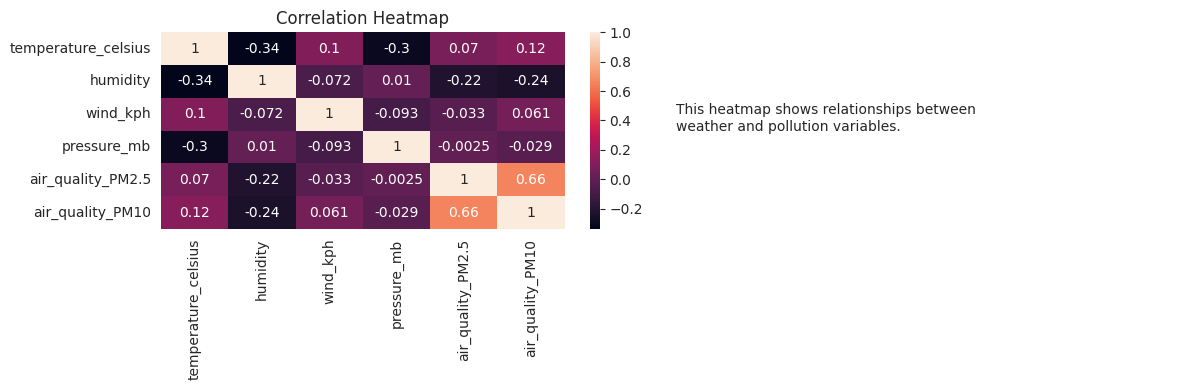

In [15]:
 #Correlation Heatmap
fig, ax = plt.subplots(1, 2, figsize=(12,4))

sns.heatmap(
    df[['temperature_celsius','humidity','wind_kph','pressure_mb',
        'air_quality_PM2.5','air_quality_PM10']].corr(),
    annot=True, ax=ax[0]
)

ax[0].set_title("Correlation Heatmap")

ax[1].axis('off')
ax[1].text(0, 0.5,
           "This heatmap shows relationships between\n"
           "weather and pollution variables.",
           fontsize=10)

plt.tight_layout()
plt.show()

In [16]:
#Correlation Analysis

corr = df[['temperature_celsius','air_quality_PM2.5','air_quality_PM10']].corr()
print(corr)

                     temperature_celsius  air_quality_PM2.5  air_quality_PM10
temperature_celsius             1.000000           0.069811          0.117800
air_quality_PM2.5               0.069811           1.000000          0.657463
air_quality_PM10                0.117800           0.657463          1.000000
